# Comparing decomposition methods for unitary matrices and their implementation in integrated photonics
- **Authors:** Andrea Barletta, Yanlong Wang
- **Abstract:** In our project we will compare the fidelity of three different architectures for universal multiport interferometers, used to perform any unitary or linear transformation. In particular we will focus on comparing the traditional Reck and Clements architectures with a Universal Generalized Mach–Zehnder Interferometer (UGMZI) architecture, inspired by the work of P. Dita, which allows for a fidelity restoration mechanism

## Imports and Helper functions

### Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from circuit.interferometer import interferometer as itf
from circuit.component import component as cmp
from circuit.component import component_type as cmp_type

### Utils

In [3]:
# Set seed globally for reproducibility
np.random.seed(42)

# Function to generate a random unitary matrix of size N x N
def random_unitary(N):
    X = np.zeros([N, N], dtype=np.complex128)
    for ii in range(N):
        for jj in range(N):
            X[ii, jj] = (np.random.normal() + 1j * np.random.normal()) / np.sqrt(2)

    q, r = np.linalg.qr(X)
    r = np.diag(np.divide(np.diag(r), abs(np.diag(r))))
    U = np.matmul(q, r)

    return U

# Function to get arctangent of the absolute ratio of two numbers
def my_atan(x1, x2):
    if x2 != 0:
        return np.arctan(abs(x1/x2))
    else:
        return np.pi/2

# Function to get the angle of the ratio of two complex numbers
def my_angle(x1, x2):
    if x2 != 0:
        return np.angle(x1/x2)
    else:
        return 0

## Building blocks

The building blocks of the photonic circuit are defined in the `component.py` file. The main components are:

### Beam splitters

We will use 2x2 beam splitters with tunable reflectivity and with a phase shifter at one of the inputs.\\
Its graphical representation and transfer function is the following:

<p align="center">
    <img src="images/beamsplitter.svg?1" width="80%" />
</p>

*Note* We could also use MZI instead of Beam splitters, as they are equivalent (up to a change of parameters), however beam splitters are more suitable as their parameters are easier to obtain from the math formulations

### Phase shiters

We will use tunable phase shifters acting on one mode at a time.\\
Its graphical representation and transfer function is the following:

<p align="center">
    <img src="images/phaseshifter.svg" width="80%" />
</p>

### Losses

We will model losses as described in [3], where we will introduce a component where the loss occurs.
Its graphical representation and transfer function is the following:

<p align="center">
    <img src="images/losselement.svg" width="80%" />
</p>

## Math preliminaries

### Givens rotation

A Givens rotation is a rotation in the plane spanned by two coordinates axes. The main use of Givens rotations is to transform vectors or matrices into a special form with zeros in certain coefficients.<br>
A Givens rotation acting on row $r$ and column $c$ acting on a $N\times N$ matrix is defined as follows
$$

T_{c,r}(\theta,\varphi)=\left[
    \begin{array}{ccccc}
    I_{c-1} & 0 & \dots & 0 & 0\\
    0 & e^{i\varphi}\cos(\theta) & \dots & -\sin(\theta) & 0\\
    \vdots & \vdots & I_{r-c-1} & \vdots & \vdots \\
    0 & e^{i\varphi}\sin(\theta) & \dots & \cos(\theta) & 0\\
    0 & 0 & \dots & 0 & I_{N-r}\\
    \end{array}
\right]
$$

It's immediate to notice how a Givens rotation can be imlemented with a single beam splitter, acting on mode $c$ and $r$ m with the same exact parameters as the rotation.

In particular, we will use Given rotations to nullify a specific element of a matrix

### The unitary group $U(N)$


The main concepts required for understanding how the decompositions work are the following:
1) **Unitary property**: Given a matrix $A\in U(N)$, and denoting with $A^\dagger$ its adjoint (conjugate transpose), we have the following $$AA^\dagger=A^\dagger A=I_N$$
2) **Group properies**: Given two unitary matrices, their product is a unitary matrix, that is
$$A,B\in U(N) \implies AB,BA\in U(N)$$
3) **Multiplication with diagonal matrix**: Multiplying a matrix by a diagonal matrix on the left, we obtain a matrix where each row $k$ is multilied by the diagonal element in position $d_{kk}$. Multiplying on the right yields the same result, except for columns.<br><br>
4) **Transitive action**: $U(N)$, which is $\simeq Aut\left(\mathcal{H}(\mathbb{C^N})\right)$, acts transitively on the unit sphere $\mathbb{S}_{2n-1}\subseteq \mathcal{H}(\mathbb{C^N})$<br><br>

Properties $3)$ and $4)$ will be used extensively in the UGMZI decomposition scheme

## Reck's Method

### Idea

The idea of Reck's method is to iteratively apply Givens rotations to cancel all the elements except the ones on the diagonal.<br>
That is, we will obtain the following:
$$
 U(N)R_NR_{N-1}\dots R_2 = diag\left(e^{i\varphi_1},e^{i\varphi_2},\dots,e^{i\varphi_N}\right)
$$

The matrix $R_j$ acts on $U(N)$ by eliminating all elements in row and column $j$, with the exception of the element in position $(j,j)$<br>
For example,
$$
U(4)R_4 = \left[
    \begin{array}{cccc}
        * & * & * & 0\\
        * & * & * & 0\\
        * & * & * & 0\\
        0 & 0 & 0 & e^{i\varphi_4}
    \end{array}
\right]
$$

We can further decompose the matrices $R_j$ as a product of (adjoint) Givens rotations as follows:
$$
    R_j = \prod_{k=j-1}^{1} T_{j,k}^\dagger(\theta_k,\varphi_k)
$$
where
$$
T^\dagger_{j,k}(\theta_k, \phi_k) =\left[
    \begin{array}{ccccc}
    I_{j-1} & 0 & \dots & 0\\
    0 & e^{-i\varphi}\cos(\theta) & e^{-i\varphi}\sin(\theta) & \vdots\\
    \vdots & -\sin(\theta) & \cos(\theta) & \vdots\\
    0  & \dots & \dots & I_{N-k}\\
    \end{array}
\right]
$$

From the unitarity of the operators $R_j$, we get the desired decompositon
$$
    U(N) = diag\left(e^{i\varphi_1},e^{i\varphi_2},\dots,e^{i\varphi_N}\right)\prod_{j=N}^{2}\prod_{k=1}^{j-1}T_{j,k}(\theta_{j,k},\varphi_{j,k})
$$

The implementation in photonics is immediate: The matrices $T_{j,k}(\theta_{j,k},\varphi_{j,k})$ are beam splitter, the diagonal matrix is an array of phase shifters<br><br>
Moreover, we see how the total number of beam splitter is $\frac{N(N-1)}{2}$

### Determining the parameters

Since for row $k$ we want columns $j\neq k$ to be 0, we can compute the $\theta$ and $\varphi$ parameters by imposing the following equality, obtained from the matrix $T_{j,k}^\dagger(\theta_k,\varphi_k)$ acting on $U$ on the right:
$$
x_j \cos(\theta) - x_k e^{-i\phi} \sin(\theta) = 0
$$

We can therefore derive the following values for $\theta$ and $\varphi$:
$$
\begin{aligned}
    \theta &= \arctan \left( \left| \frac{x_k}{x_j} \right| \right) \\\\
    \varphi   &= -\arg \left( -\frac{x_k}{x_j} \right)
\end{aligned}

### Topology

From the math formulation and the observations about the implementation of each transformation as a photonic component, we obtain the following topology for the Reck's decomposition

<p align="center">
    <img src="images/reck.svg" width="60%"/>
</p>

### Losses

We will model losses as an element after each beam splitter affecting both modes with the following transmission matrix

$$
L(l) = \left[
    \begin{array}{cc}
        \sqrt{l} & 0 \\ 
        0 & \sqrt{l}
    \end{array}
\right]
$$

### Python implementation

In [4]:
def decompose_reck(U,verbose=False):
    if verbose:
        print(f"U {np.round(U,3)}\n")
    I = itf()
    N = int(np.sqrt(U.size))
    # Loop over each layer in the Reck triangular decomposition
    for i in range(N-1):
        # Each layer acts on a decreasing number of modes
        for j in range(N-1-i):
            modes = [N - j - 1, N - j]
            # Calculate the theta and phi for the inverse T matrix
            theta = my_atan(U[i, N - 1 - j], U[i, N - 2 - j])
            phi = -my_angle(-U[i, N - 1 - j], U[i, N - 2 - j])
            invT = np.eye(N, dtype=np.complex128)
            # Fill in the inverse T matrix based on the previous results
            invT[modes[0]-1, modes[0]-1] = np.exp(-1j * phi) * np.cos(theta)
            invT[modes[0]-1, modes[1]-1] = np.exp(-1j * phi) * np.sin(theta)
            invT[modes[1]-1, modes[0]-1] = -np.sin(theta)
            invT[modes[1]-1, modes[1]-1] = np.cos(theta)
            # Apply the inverse T matrix to the unitary matrix from right (affect 2 columns of U)
            U = np.matmul(U, invT)
            # Print to verify matrix after applying the inverse T matrix each step
            if verbose: 
                print(f"U {np.round(U,3)}\n")
            I.comp_list.append(cmp(cmp_type.BEAM_SPLITTER, (modes), (theta, phi)))
            for mode in modes:
                I.comp_list.append(cmp(cmp_type.LOSS_ELEMENT, (mode,), ()))
            # Add a loss term
    phases = np.diag(U)
    I.output_phases = [np.angle(i) for i in phases]
    return I

Once we have our Reck decomposition function, we can use the interferometer `.calculate_transformation()` method to compute the reconstructed unitary, and also use the `.draw()` function to see the layout

For example:

U [[ 0.334-0.093j  0.112+0.556j  0.208-0.372j  0.607+0.095j]
 [-0.316+0.365j  0.308-0.082j -0.124-0.663j -0.182+0.421j]
 [-0.681+0.211j  0.041-0.139j  0.201+0.235j  0.61 -0.057j]
 [-0.366+0.075j -0.417+0.618j -0.516-0.038j -0.096-0.167j]]

U [[ 0.334-0.093j  0.112+0.556j -0.738-0.115j -0.   -0.j   ]
 [-0.316+0.365j  0.308-0.082j -0.18 -0.148j -0.579+0.526j]
 [-0.681+0.211j  0.041-0.139j -0.416-0.107j  0.471-0.255j]
 [-0.366+0.075j -0.417+0.618j  0.161+0.421j  0.063+0.313j]]

U [[ 0.334-0.093j  0.927+0.145j -0.   -0.j    -0.   -0.j   ]
 [-0.316+0.365j  0.162-0.074j -0.085-0.342j -0.579+0.526j]
 [-0.681+0.211j  0.261+0.033j -0.343-0.134j  0.471-0.255j]
 [-0.366+0.075j  0.134+0.031j  0.444+0.737j  0.063+0.313j]]

U [[-0.988-0.154j -0.   +0.j    -0.   -0.j    -0.   -0.j   ]
 [-0.   +0.j     0.467-0.215j -0.085-0.342j -0.579+0.526j]
 [ 0.   -0.j     0.754+0.095j -0.343-0.134j  0.471-0.255j]
 [ 0.   -0.j     0.388+0.089j  0.444+0.737j  0.063+0.313j]]

U [[-0.988-0.154j -0.   +0.j     0.   -0

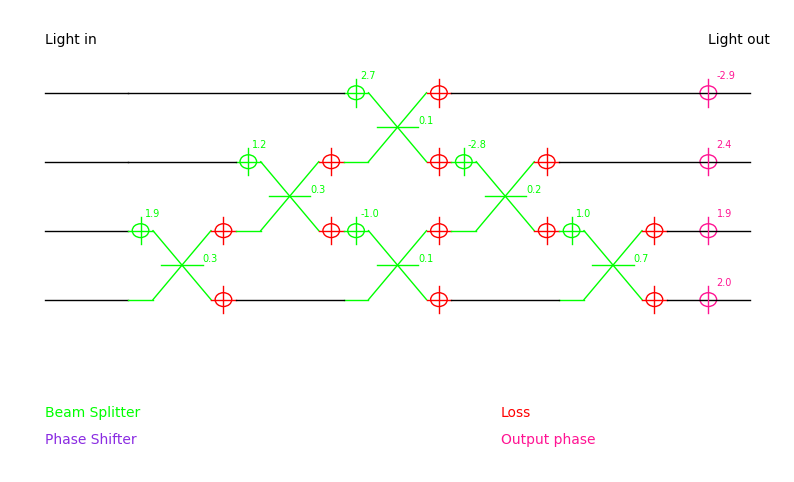

Frobenius norm: 6.967630807752464e-16


In [5]:
U = random_unitary(4)
I = decompose_reck(U,verbose=True)
I.draw()

Uexp = I.calculate_transformation()

print("Frobenius norm:", np.linalg.norm(Uexp - U))

As indicated by the Frobenius norm, we have a good approximation of the orginal matrix

## Clements' Method

### Idea

Clements' method is an optimized arrangement beyond Reck's.<br>
This method uses both $T$ from left effecting the rows, and $T^\dagger$ matrices from the right effecting the columns, yielding a different elimination order.<br>
In particular, we will obtain a decomposition in the form:
$$
\left(\prod_{(i,j)\in C_1}T_{i,j}(\theta_{i,j},\varphi_{i,j})\right) U(N) \left(\prod_{(k,l)\in C_2}T_{k,l}^\dagger(\theta_{k,l},\varphi_{k,l})\right) = A
$$
where $A$ is an upper triangular matrix, and $C_1$ $C_2$ are a suitable set of indices. <br>
Notice how we don't obtain a diagonal matrix at the end of the decomposition. However, using the property that, up to a parameter change, $T^\dagger_{m,n}(\theta,\varphi)A=A' T_{m,n}(\theta',\varphi')$, we obtain the following formulation
$$
U(N) = diag\left(e^{i\varphi_1},e^{i\varphi_2},\dots,e^{i\varphi_N}\right)\left(\prod_{(i,j)\in C_1}^{\text{reverse}}T_{i,j}(\theta_{i,j},\varphi_{i,j})\right)\left(\prod_{(k,l)\in C_2}^{\text{reverse}}T_{k,l}(\theta_{k,l},\varphi_{k,l})\right)
$$

For clarity, we will proceed with a guided example on a matrix $U\in U(4)$
$$
U=
\left[
    \begin{array}{cccc}
    * & * & * & * \\
    * & * & * & * \\
    * & * & * & * \\
    * & * & * & *
    \end{array}
\right]
\rightarrow
UT_{2,1}^\dagger = 
\left[
    \begin{array}{cccc}
    * & * & * & * \\
    * & * & * & * \\
    * & * & * & * \\
    0 & * & * & *
    \end{array}
\right]
\rightarrow
T_{3,2}UT_{2,1}^\dagger = 
\left[
    \begin{array}{cccc}
    * & * & * & * \\
    * & * & * & * \\
    0 & * & * & * \\
    0 & * & * & *
    \end{array}
\right]
\rightarrow
T_{4,3}T_{3,2}UT_{2,1}^\dagger = 
\left[
    \begin{array}{cccc}
    * & * & * & * \\
    * & * & * & * \\
    0 & * & * & * \\
    0 & 0 & * & *
    \end{array}
\right]
$$
$$
\rightarrow
T_{4,3}T_{3,2}UT_{2,1}^\dagger T_{4,3}^\dagger = 
\left[
    \begin{array}{cccc}
    * & * & * & * \\
    * & * & * & * \\
    0 & * & * & * \\
    0 & 0 & 0 & *
    \end{array}
\right]
\rightarrow
T_{4,3}T_{3,2}UT_{2,1}^\dagger T_{4,3}^\dagger T_{3,2}^\dagger = 
\left[
    \begin{array}{cccc}
    * & * & * & * \\
    * & * & * & * \\
    0 & 0 & * & * \\
    0 & 0 & 0 & *
    \end{array}
\right]
\rightarrow
T_{4,3}T_{3,2}UT_{2,1}^\dagger T_{4,3}^\dagger T_{3,2}^\dagger T_{2,1}^\dagger= 
\left[
    \begin{array}{cccc}
    * & * & * & * \\
    0 & * & * & * \\
    0 & 0 & * & * \\
    0 & 0 & 0 & *
    \end{array}
\right]
$$

As we can see, we will proceed in a zig-zag manner, starting from the bottom left-most corner.<br><br>
The total number of beam splitters is $\frac{N(N-1)}{2}$, which is same as Reck's method but as we will see it yields a more equal distribution of the beam splitters (and as a consequence of the losses)

### Determining the parameters

The $\theta$ and $\varphi$ parameters for $T$ and $T^\dagger$ matrices are determined by elimination conditions on the elements of the original matrix:

- $T_{j,k}(\theta,\varphi)$ matrices applied on the left give the following equality:
    $$
        x_j e^{i\varphi} \sin(\theta) + x_k \cos(\theta) = 0
    $$

    We can therefore derive the following values for $\theta$ and $\varphi$:

    $$
        \begin{aligned}
            \theta &= \arctan \left( \left| \frac{x_k}{x_j} \right| \right) \\\\
            \varphi   &= \arg \left( -\frac{x_k}{x_j} \right)
        \end{aligned}
    $$

- $T^\dagger_{j,k}(\theta,\varphi)$ matrices applied on right give the following equality:
    $$
        x_j e^{-i\phi} \cos(\theta) - x_k \sin(\theta) = 0
    $$

    We can therefore derive the following values for $\theta$ and $\varphi$:

    $$
    \begin{aligned}
        \theta &= \arctan \left( \left| \frac{x_j}{x_k} \right| \right) \\\\
        \varphi   &= \arg \left( \frac{x_j}{x_k} \right)
    \end{aligned}
    $$

### Topology

From the math formulation and the observations about the implementation of each transformation as a photonic component, we obtain the following topology for the Reck's decomposition

<p align="center">
    <img src="images/clements.svg" width="60%"/>
</p>

### Losses

We will model losses as an element after each beam splitter affecting both modes with the following transmission matrix

$$
L(l) = \left[
    \begin{array}{cc}
        \sqrt{l} & 0 \\ 
        0 & \sqrt{l}
    \end{array}
\right]
$$

### Python implementation

In [6]:
def decompose_clements(U, verbose=False):
    if verbose:
        print(f"U {np.round(U,3)}\n")
    I = itf()
    N = int(np.sqrt(U.size))
    left_T = []
    for i in range(N-1):
        # Determine if using T or T-inverse based on the layer index
        if np.mod(i, 2) == 0:
            for j in range(i+1):
                # The sequence is an offdiagonal shape, from right column elimination to left column elimination
                modes = [i - j + 1, i + 2 - j]
                # Calculate theta and phi for the T inverse matrix
                theta = my_atan(U[N-1-j, i-j], U[N-1-j, i-j+1])
                phi = my_angle(U[N-1-j, i-j], U[N-1-j, i-j+1])
                invT = np.eye(N, dtype=np.complex128)
                invT[modes[0]-1, modes[0]-1] = np.exp(-1j * phi) * np.cos(theta)
                invT[modes[0]-1, modes[1]-1] = np.exp(-1j * phi) * np.sin(theta)
                invT[modes[1]-1, modes[0]-1] = -np.sin(theta)
                invT[modes[1]-1, modes[1]-1] = np.cos(theta)
                # Apply the inverse T matrix to the unitary matrix from right (affect 2 columns of U)
                U = np.matmul(U, invT)
                if verbose: 
                    print(f"U {np.round(U,3)}\n")
                I.comp_list.append(cmp(cmp_type.BEAM_SPLITTER, (modes), (theta, phi)))
                for mode in modes:
                    I.comp_list.append(cmp(cmp_type.LOSS_ELEMENT, (mode,), ()))
        else:
            for j in range(i+1):
                # The sequence is an offdiagonal shape, from top row elimination to bottom row elimination
                modes = [N+j-i-1, N+j-i]
                # Calculate theta and phi for the T matrix
                theta = my_atan(U[N+j-i-1, j], U[N+j-i-2, j])
                phi = my_angle(-U[N+j-i-1, j], U[N+j-i-2, j])
                T = np.eye(N, dtype=np.complex128)
                T[modes[0]-1, modes[0]-1] = np.exp(1j * phi) * np.cos(theta)
                T[modes[0]-1, modes[1]-1] = -np.sin(theta)
                T[modes[1]-1, modes[0]-1] = np.exp(1j * phi) * np.sin(theta)
                T[modes[1]-1, modes[1]-1] = np.cos(theta)
                # Apply the T matrix to the unitary matrix from left (affect 2 rows of U)
                U = np.matmul(T, U)
                if verbose: 
                    print(f"U {np.round(U,3)}\n")
                left_T.append(cmp(cmp_type.BEAM_SPLITTER, (modes), (theta, phi)))

    for comp in np.flip(left_T, 0):
        modes = [int(comp.modes[0]), int(comp.modes[1])]
        invT = np.eye(N, dtype=np.complex128)
        invT[modes[0]-1, modes[0]-1] = np.exp(-1j * comp.params[1]) * np.cos(comp.params[0])
        invT[modes[0]-1, modes[1]-1] = np.exp(-1j * comp.params[1]) * np.sin(comp.params[0])
        invT[modes[1]-1, modes[0]-1] = -np.sin(comp.params[0])
        invT[modes[1]-1, modes[1]-1] = np.cos(comp.params[0])
        U = np.matmul(invT, U)
        theta = my_atan(U[modes[1]-1, modes[0]-1], U[modes[1]-1, modes[1]-1])
        phi = my_angle(U[modes[1]-1, modes[0]-1], U[modes[1]-1, modes[1]-1])
        invT[modes[0]-1, modes[0]-1] = np.exp(-1j * phi) * np.cos(theta)
        invT[modes[0]-1, modes[1]-1] = np.exp(-1j * phi) * np.sin(theta)
        invT[modes[1]-1, modes[0]-1] = -np.sin(theta)
        invT[modes[1]-1, modes[1]-1] = np.cos(theta)
        U = np.matmul(U, invT)
        I.comp_list.append(cmp(cmp_type.BEAM_SPLITTER, (modes), (theta, phi)))
        for mode in modes:
                I.comp_list.append(cmp(cmp_type.LOSS_ELEMENT, (mode,), ()))
    phases = np.diag(U)
    I.output_phases = [np.angle(i) for i in phases]
    return I

Once we have our Clements decomposition function, we can use the interferometer `.calculate_transformation()` method to compute the reconstructed unitary, and also use the `.draw()` function to see the layout

For example:

U [[ 0.115-0.588j -0.28 +0.001j -0.237+0.408j  0.22 +0.54j ]
 [-0.28 -0.103j  0.173+0.596j -0.525-0.476j  0.031+0.152j]
 [ 0.271+0.453j  0.148+0.055j  0.264-0.207j  0.493+0.584j]
 [-0.012+0.522j -0.703+0.132j -0.366+0.17j   0.171-0.152j]]

U [[ 0.649-0.009j  0.128-0.005j -0.237+0.408j  0.22 +0.54j ]
 [-0.067-0.59j   0.165+0.307j -0.525-0.476j  0.031+0.152j]
 [-0.4  +0.258j -0.108+0.256j  0.264-0.207j  0.493+0.584j]
 [-0.   +0.j    -0.871+0.164j -0.366+0.17j   0.171-0.152j]]

U [[ 0.649-0.009j  0.128-0.005j -0.237+0.408j  0.22 +0.54j ]
 [ 0.639-0.412j -0.09 +0.061j -0.013-0.402j -0.403-0.291j]
 [ 0.   +0.j    -0.211+0.378j  0.327-0.588j  0.308+0.515j]
 [-0.   +0.j    -0.871+0.164j -0.366+0.17j   0.171-0.152j]]

U [[ 0.649-0.009j  0.128-0.005j -0.237+0.408j  0.22 +0.54j ]
 [ 0.639-0.412j -0.09 +0.061j -0.013-0.402j -0.403-0.291j]
 [ 0.   -0.j     0.969-0.182j  0.039-0.098j -0.067-0.112j]
 [-0.   +0.j     0.   -0.j    -0.755+0.187j  0.253-0.576j]]

U [[ 0.649-0.009j  0.128-0.005j -0.283-0

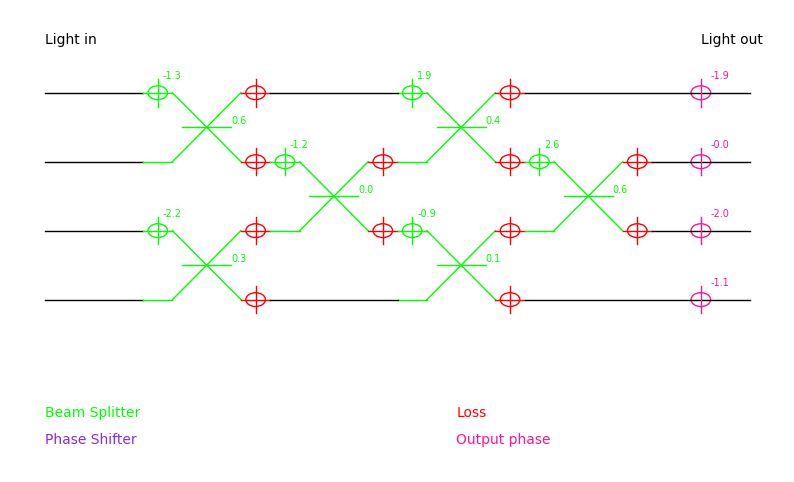

Frobenius norm: 5.724745170685498e-16


In [7]:
U = random_unitary(4)
I = decompose_clements(U,verbose=True)
I.draw()
Uexp = I.calculate_transformation()

print("Frobenius norm:", np.linalg.norm(Uexp - U))

As indicated by the Frobenius norm, we have a good approximation of the orginal matrix

## UGMZI Decomposition

### Idea

This method is inspired by the work of P. Dita [4], where in his paper he discusses about the problem of factorizing unitary matrices as a product of diagonal and orthogonal matrices.<br>
In particular he proves the existance of a decomposition in the following formulation

$$
 U = d_n\mathcal{O}_nd_{n-1}^1\mathcal{O}_{n-1}^1\dots d_{2}^{n-2}\mathcal{O}_2^{n-2}d_1^{n-1}
$$

where matrices $d_j^k$ and $O_j^k$ are block matrices in the following form:

$$
\mathcal{d}_{j}^k = \begin{bmatrix} I_k & 0 \\ 0 & d_{j}\end{bmatrix} \qquad \mathcal{O}_{j}^k = \begin{bmatrix} I_k & 0 \\ 0 & O_{j}\end{bmatrix}
$$

In particular, the matrices $O_j$ can be further factorized as a product of Givens rotations, that is
$$
\mathcal{O}_{j} = T_{j-1,j}(\theta_1,0)T_{j-2,j-1}(\theta_2,0)\dots T_{1,2}(\theta_{j-1},0)
$$

The decomposition is divided in two steps:
- **Rotate column** Due to the properties of the unitary group, there always exist a transformation (i.e. a right-multiplication by a diagonal matrix) that makes the $i$-th column of a unitary matrix real and positive. These transformations are necessary to uniquely determine the next step<br><br>
- **Zero row and column** As we saw in the other decompositions, we can apply givens rotations to eliminate an arbitrary element in the matrix, and in particular we will eliminate all the rows and columns, except for elements on the diagonal. In other words, we are looking at transformation like the following

$$
\left[
    \begin{array}{cccc}
    * & * & * & * \\
    * & * & * & * \\
    * & * & * & * \\
    * & * & * & *
    \end{array}
\right]
\rightarrow
\left[
    \begin{array}{cccc}
    1 & 0 & 0 & 0 \\
    0 & * & * & * \\
    0 & * & * & * \\
    0 & * & * & *
    \end{array}
\right]
$$

By iteratively alternating the two steps, we construct a decompositions that transforms the orginal matrix as follows

$$
\left[
    \begin{array}{cccc}
    * & * & * & * \\
    * & * & * & * \\
    * & * & * & * \\
    * & * & * & *
    \end{array}
\right]
\begin{array}{c}
    d\\
    \rightarrow
\end{array}
\left[
    \begin{array}{cccc}
    + & * & * & * \\
    + & * & * & * \\
    + & * & * & * \\
    + & * & * & *
    \end{array}
\right]
\begin{array}{c}
    \mathcal{O}\\
    \rightarrow
\end{array}
\left[
    \begin{array}{cccc}
    1 & 0 & 0 & 0 \\
    0 & * & * & * \\
    0 & * & * & * \\
    0 & * & * & *
    \end{array}
\right]
\begin{array}{c}
    d\\
    \rightarrow
\end{array}
\left[
    \begin{array}{cccc}
    1 & 0 & 0 & 0 \\
    0 & + & * & * \\
    0 & + & * & * \\
    0 & + & * & *
    \end{array}
\right]
$$
$$
\begin{array}{c}
    \mathcal{O}\\
    \rightarrow
\end{array}
\left[
    \begin{array}{cccc}
    1 & 0 & 0 & 0 \\
    0 & 1 & 0 & 0 \\
    0 & 0 & * & * \\
    0 & 0 & * & *
    \end{array}
\right]
\begin{array}{c}
    d\\
    \rightarrow
\end{array}
\left[
    \begin{array}{cccc}
    1 & 0 & 0 & 0 \\
    0 & 1 & 0 & 0 \\
    0 & 0 & + & * \\
    0 & 0 & + & *
    \end{array}
\right]
\begin{array}{cccc}
    \mathcal{O}\\
    \rightarrow
\end{array}
\left[
    \begin{array}{cccc}
    1 & 0 & 0 & 0 \\
    0 & 1 & 0 & 0 \\
    0 & 0 & 1 & 0 \\
    0 & 0 & 0 & *
    \end{array}
\right]
\begin{array}{c}
    d\\
    \rightarrow
\end{array}
\left[
    \begin{array}{cccc}
    1 & 0 & 0 & 0 \\
    0 & 1 & 0 & 0 \\
    0 & 0 & 1 & 0 \\
    0 & 0 & 0 & +
    \end{array}
\right]
\begin{array}{cccc}
    \mathcal{O}\\
    \rightarrow
\end{array}
\left[
    \begin{array}{cccc}
    1 & 0 & 0 & 0 \\
    0 & 1 & 0 & 0 \\
    0 & 0 & 1 & 0 \\
    0 & 0 & 0 & 1
    \end{array}
\right]
$$



### Determining the parameters

We have two types of parameters to determine:
- **Parameters for d** Knowing that multiplying on the right by a digonal matrix affects entire rows, it's trivial to obtain
$$
    d_j^k=diag(1,\dots,1,e^{i\varphi_1},\dots,e^{i\varphi_j})\qquad \varphi_i = arg(x_{j,i})
$$
- **Parameters for $\mathcal{O}$** We saw how these types of transformations can be decomposed into Givens rotations. Therefore, the parameters are determines exactly the same as with previous decomposition methods, with the exception that now we only have 1 parameter instead of 2
$$
\theta = \arctan \left( \left| \frac{x_j}{x_k} \right| \right) \\\\
$$

### Topology

Given the block nature of the transformations, it's useful to consider the decomposition as a cascade of size-increasing blocks, which consist of the beams splitter representing the Givens rotations and the array of phase shifters representing the diagonal matrices

<p align="center">
    <img src="images/ugmzi.svg" width="70%"/>
</p>

Although the topology seems similar to Reck's decomposition, we will see in the fidelity chapter how to exploit this scheme for fidelity restoration

### Losses

We will model losses as an element after each $n\times n$ block, affecting all the $n$ modes with the following transmission matrix

$$
L^n(l) = \sqrt{l}\ I_n
$$

The reason for this is because, in practice, we would implement the blocks as an $n\times n$ MMI, followed by an array of phase shifter, followed by an $n\times n$ MMZI, followed by another array of phase shifter (corresponding to the one we have)

### Python implementation

In [8]:
def decompose_ugmzi(U,verbose=False):
    if verbose:
        print(f"U {np.round(U,3)}\n")
    N = int(np.sqrt(U.size))
    I = itf()
    # Notice that we will decompose from n->1, so we will have to insert the elements in the circuit in reverse order
    # Extract the output phases (we will add these at the end)
    phases = np.angle(U[:, 0])
    Dd = np.diag(np.exp(-1j*phases))
    U = Dd @ U
    I.output_phases = phases
    for i in range(len(phases)):
        I.comp_list.insert(0, cmp(cmp_type.LOSS_ELEMENT, (N-i,), ()))
    I.comp_list.insert(0, cmp(cmp_type.BARRIER, (-1,), ()))
    if verbose:
        print(f"U {np.round(U,3)}\n")
    for n in range(N, 1, -1):
        # Compute the appropriate Givens rotations to have the matrix in the form [1 0; 0 U']
        for i in range(n-1, 0, -1):
            u = U[:, 0]
            theta = my_atan(u[i], u[i-1])
            O = np.eye(n, dtype=np.complex128)
            # theta = my_atan(u[j], u[j-1])
            O[i-1][i-1] = np.cos(theta)
            O[i-1][i] = np.sin(theta)
            O[i][i-1] = -np.sin(theta)
            O[i][i] = np.cos(theta)
            U = O @ U
            I.comp_list.insert(0,cmp(cmp_type.BEAM_SPLITTER, (N-n+i, N-n+i+1), (theta, 0)))

            if verbose:
                print(f"U {np.round(U,3)}\n")
                

        # Resize the matrix U
        U = U[1:, 1:]
        
        # Extract the phases to make the first column real and positive
        phases = np.angle(U[:, 0])
        Dd = np.diag(np.exp(-1j*phases))
        U = Dd @ U
        phases = phases[::-1]
        for i in range(len(phases)):
            I.comp_list.insert(0, cmp(cmp_type.LOSS_ELEMENT, (N-i,), ()))
            I.comp_list.insert(1,cmp(cmp_type.PHASE_SHIFTER, (N-i,), (phases[i],)))
            
        I.comp_list.insert(0, cmp(cmp_type.BARRIER, (-1,), ()))
        
        if verbose:
                print(f"U {np.round(U,3)}\n")
        

    #Insert the loss related to the first block
    # I.comp_list.insert(1, cmp(cmp_type.LOSS_ELEMENT, (N,), ()))
    return I

Once we have our UGMZI decomposition function, we can use the interferometer `.calculate_transformation()` method to compute the reconstructed unitary, and also use the `.draw()` function to see the layout

For example:

U [[ 0.106+0.093j -0.042-0.124j -0.679-0.163j -0.344-0.597j]
 [-0.057+0.144j  0.748+0.01j   0.179-0.315j -0.516+0.137j]
 [ 0.021+0.878j -0.107-0.224j  0.269+0.256j -0.024-0.167j]
 [ 0.282-0.324j  0.442-0.408j  0.204+0.449j  0.197-0.414j]]

U [[ 0.141-0.j    -0.113-0.065j -0.617+0.327j -0.653-0.22j ]
 [ 0.155+0.j    -0.268-0.698j -0.359-0.05j   0.319+0.429j]
 [ 0.878-0.j    -0.227+0.102j  0.263-0.263j -0.168+0.02j ]
 [ 0.43 +0.j     0.598+0.065j -0.205+0.448j  0.442-0.123j]]

U [[ 0.141-0.j    -0.113-0.065j -0.617+0.327j -0.653-0.22j ]
 [ 0.155+0.j    -0.268-0.698j -0.359-0.05j   0.319+0.429j]
 [ 0.978-0.j     0.059+0.12j   0.146-0.039j  0.043-0.036j]
 [ 0.   +0.j     0.637+0.014j -0.3  +0.518j  0.471-0.119j]]

U [[ 0.141-0.j    -0.113-0.065j -0.617+0.327j -0.653-0.22j ]
 [ 0.99 -0.j     0.016+0.009j  0.088-0.047j  0.093+0.031j]
 [ 0.   -0.j     0.274+0.708j  0.377+0.043j -0.308-0.429j]
 [ 0.   +0.j     0.637+0.014j -0.3  +0.518j  0.471-0.119j]]

U [[ 1.   -0.j    -0.   -0.j    -0.   -0

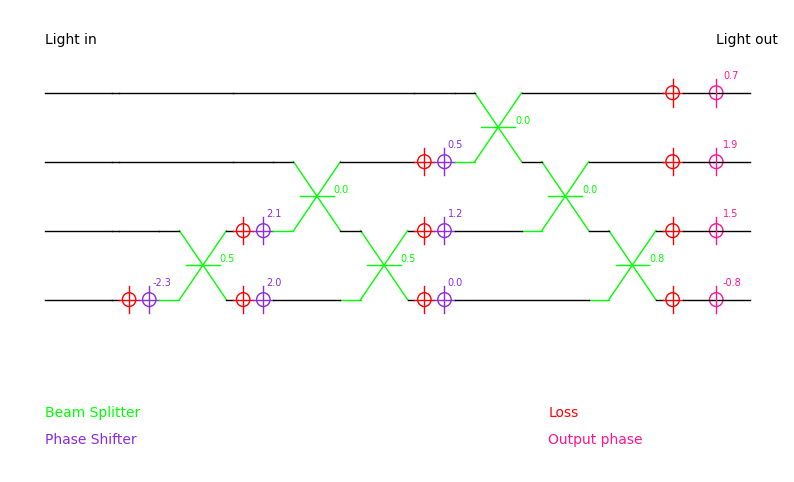

Frobenius norm: 6.85382637483426e-16


In [9]:
U = random_unitary(4)
I = decompose_ugmzi(U,verbose=True)
I.draw()
Uexp = I.calculate_transformation()

print("Frobenius norm:", np.linalg.norm(Uexp - U))

As indicated by the Frobenius norm, we have a good approximation of the orginal matrix

## Fidelity

### Definition

Implementation of an arbitrary unitary matrix with realistic, nonideal optical components will result in a discrepancy between the achieved and targeted matrix element values.<br>
To quantify this discrepancy, we rely on the fidelity parameter, defined as follows:

$$
F(U,U_{\text{exp}})=\left|\frac{\text{tr}(U^\dagger U_{\text{exp}})}{\sqrt{\text{tr}((U^\dagger U))\text{tr}(U_{\text{exp}}^\dagger U_{\text{exp}})}}\right|^2
$$

where $U\in U(N)$ is the targeted unitary matrix and $U_{\text{exp}}$ is its experimental counterpart.<br>
Notice that, although the matrix $U$ is unitary, it's not guaranteed that $U_{\text{exp}}$ will be too.<br>

### Python implementation

In [10]:
def Fid(U, Uexp):
    return np.abs(np.trace(U @ Uexp.conj().T) / 
      np.sqrt(
          np.trace(U @ U.conj().T)*np.trace(Uexp @ Uexp.conj().T)
      ))**2

### Fidelity restoration

The key property of the UGMZI decomposition method is that, considering $k_n$ the loss of the $n\times n$ component, we can factor it out of the decomposition as follows
$$
S_{exp}^{N-n} = k_n\left[
    \begin{array}{cc}
        k_n^{-1}I_{N_n} & 0\\
        0 & S_n
    \end{array}
\right]
$$ 
This yields the following results:
$$
U_{GMZI}^\dagger U_{exp,GMZI} = \prod_{n=1}^N k_n \cdot B_U^{-1} \qquad U_{exp,GMZI}^\dagger U_{exp,GMZI} = \prod_{n=1}^N k_n^2 \cdot\left(B_U^{-1}\right)^2
$$

where

$$
B_U^{-1} = \text{diag}\left[\prod_{n=1}^{N-1}k_n^{-1},\prod_{n=1}^{N-2}k_n^{-1},\dots,k_1^{-1},1\right]
$$

Substituting these in the fidelity equation we obtain

$$
F_{UGMZI} = \left|\frac{\sum_{l=1}^N\prod_{n=l}^N k_n}{\sqrt{N\sum_{l=1}^N\prod_{n=l}^N k_n^2}}\right|^2
$$

By applying compensating components to the input of our baseline UGMZI architecture in the form of variable optical attenuators, we can fully balances the losses, obtaining the Balanced-UGMZI (BUGMZI for short).<br>
This can be achieved by adding an array of attenuators at the beginning of our circuit, with values equal to $B_U$, as follows:

<p align="center">
    <img src="images/bugmzi.svg" width="70%"/>
</p>

For each mode, we will add an attenuator with parameter such that the total loss per mode is equal.<br>
Notice that, even though we will completely restore fidelity, the final matrix will not be equal to $U$, but will, as easly obtained by the above calculations, be equal to a scaled version of $U$ 

In [11]:
def restorer(N,LN_dB):
    voa = np.ones(N, dtype=np.float64)
    k = np.sqrt(10**(LN_dB/10))
    for i in range(1,N+1):
        voa[i-1] = k**(N-i)
    return voa

In [12]:
N = 10
LN_dB = -1.5
U = random_unitary(N)
I = decompose_ugmzi(U)
Uexp = I.calculate_transformation(LN_dB=LN_dB)
voa = restorer(N, LN_dB)
print("VOA:", voa)
print("UGMZI fidelity:", Fid(U, Uexp))
print("BUGMZI fidelity:", Fid(U, Uexp @ np.diag(voa)))
print ("Frobenius norm:", np.linalg.norm(Uexp @ np.diag(voa) - U))

VOA: [0.2113489  0.25118864 0.29853826 0.35481339 0.4216965  0.50118723
 0.59566214 0.70794578 0.84139514 1.        ]
UGMZI fidelity: 0.8104222712373853
BUGMZI fidelity: 1.0
Frobenius norm: 2.59993633497803


(Values for fidelity different from 1.0 are due to roundoff errors)

### Fidelity vs Parameters error

The first thing we want to explore is how the different methods behave when the parameters are not set exactly, which could be the result of errors in calibration.<br>
In particular, we will see how the decompositions behave with an increasing standard deviation from the ideal parameters.<br>
We will proceed with a Monte Carlo method, fixing the size of the matrices.

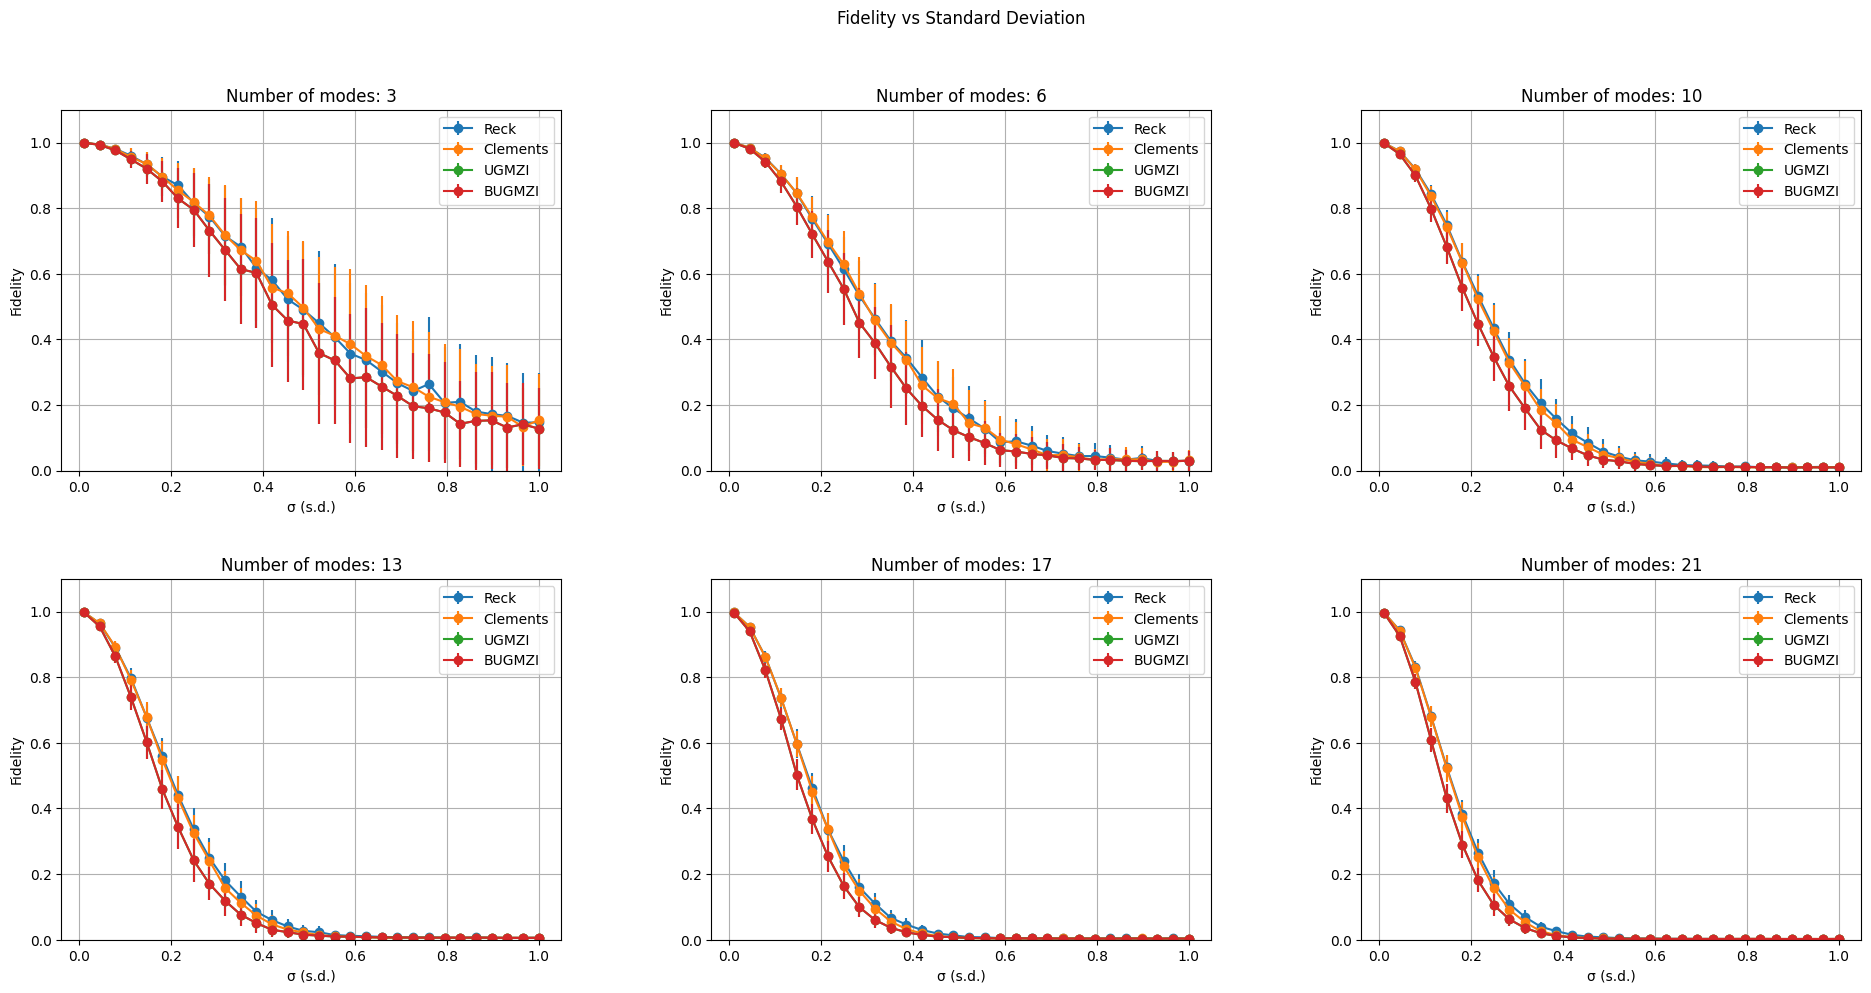

In [33]:
NUM_MODE = [int(n) for n in np.linspace(3,21,6)]
S_DEV = np.linspace(0.01, 1.0, 30)
COUNT = 200

# Matplotlib setup
plots = []
fig, plots = plt.subplots(2,3, figsize=(20, 10))
plt.subplots_adjust(left=0.05, right=0.95, bottom=0.05, wspace=0.3, hspace=0.3)
fig.suptitle('Fidelity vs Standard Deviation')
x = S_DEV

for i in range(len(NUM_MODE)):
    ax = plots[i//3, i%3]
    ax.set_title(f'Number of modes: {NUM_MODE[i]}')
    ax.set_xlabel('σ (s.d.)')
    ax.set_ylabel('Fidelity')
    ax.grid()
    ax.set_ylim(0, 1.1)
    fidelity = np.zeros((len(S_DEV), 4))
    sds = np.zeros((len(S_DEV), 4))
    
    for j in range(len(S_DEV)):
        total = np.zeros((COUNT, 4))
        for k in range(COUNT):
            # Compute the circuits
            U = random_unitary(NUM_MODE[i])
            circuit_reck = decompose_reck(U)
            circuit_clements = decompose_clements(U)
            circuit_ugmzi = decompose_ugmzi(U)
            
            # Compute the experimental transformations with parameter errors
            
            # Reck
            Uexp_reck = circuit_reck.calculate_transformation(sd=S_DEV[j])
            total[k,0] += Fid(U, Uexp_reck)
            
            # Clements
            Uexp_clements = circuit_clements.calculate_transformation(sd=S_DEV[j])
            total[k,1] += Fid(U, Uexp_clements)
            
            # UGMZI
            Uexp_ugmzi = circuit_ugmzi.calculate_transformation(sd=S_DEV[j])
            total[k,2] += Fid(U, Uexp_ugmzi)
            
            # BUGMZI
            voa = restorer(NUM_MODE[i], 0)
            Uexp_bugmzi = Uexp_ugmzi @ np.diag(voa)
            total[k,3] += Fid(U, Uexp_bugmzi)

        fidelity[j,0] = np.mean(total[:,0])
        fidelity[j,1] = np.mean(total[:,1])
        fidelity[j,2] = np.mean(total[:,2])
        fidelity[j,3] = np.mean(total[:,3])
        sds[j,0] = np.std(total[:,0])
        sds[j,1] = np.std(total[:,1])
        sds[j,2] = np.std(total[:,2])
        sds[j,3] = np.std(total[:,3])
    
    # Draw the plot
    ax.errorbar(x,fidelity[:,0], yerr=sds[:,0], marker='o')
    ax.errorbar(x,fidelity[:,1], yerr=sds[:,1], marker='o')
    ax.errorbar(x,fidelity[:,2], yerr=sds[:,2], marker='o')
    ax.errorbar(x,fidelity[:,3], yerr=sds[:,3], marker='o')

    ax.legend(['Reck', 'Clements', 'UGMZI', 'BUGMZI'])


plt.show()

As we can see, all the methods perform the same in terms of fidelity vs parameter error

### Fidelity vs Loss
We will now explore how fidelity decreases when introducing losses, and verify that our fidelity-restoring mechanism works as expected

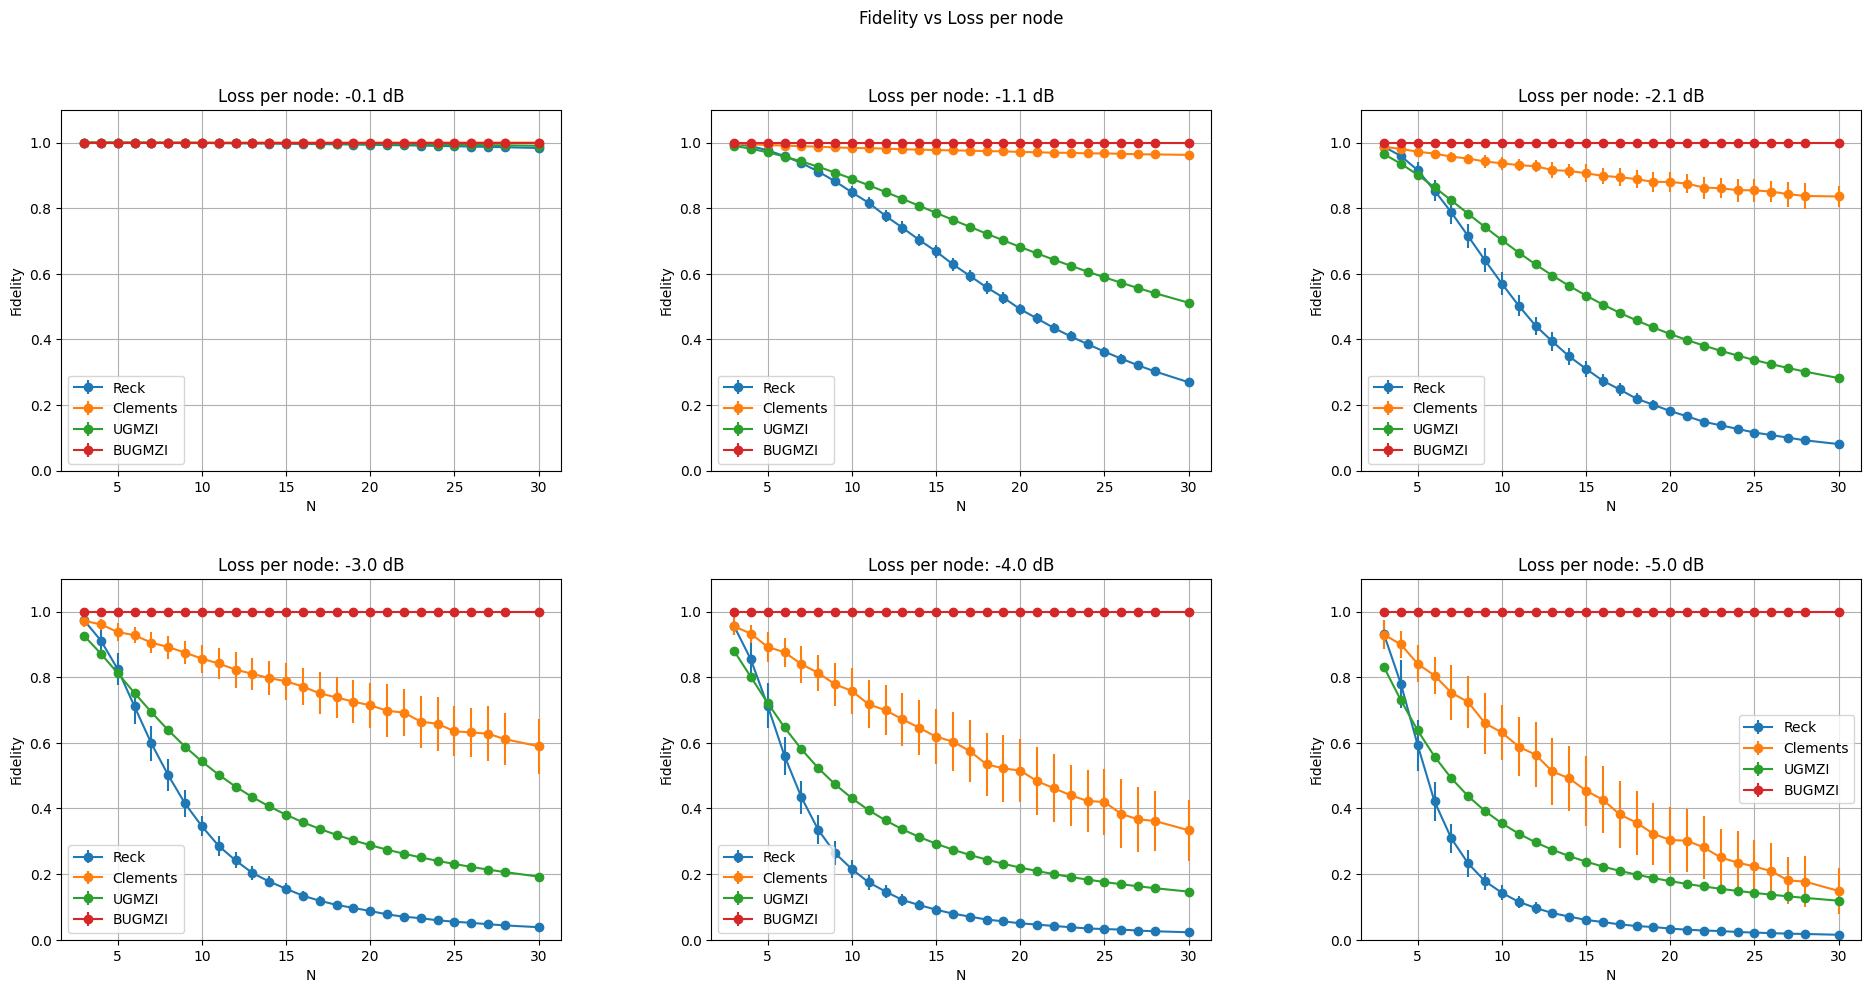

In [34]:
NUM_MODE = [int(n) for n in np.linspace(3,30,27)]
LOSSES = np.linspace(-0.1, -5.0, 6)
COUNT = 200

# Matplotlib setup
plots = []
fig, plots = plt.subplots(2,3, figsize=(20, 10))
plt.subplots_adjust(left=0.05, right=0.95, bottom=0.05, wspace=0.3, hspace=0.3)
fig.suptitle('Fidelity vs Loss per node')
x = NUM_MODE

for i in range(LOSSES.size):
    ax = plots[i//3, i%3]
    ax.set_title(f'Loss per node: {LOSSES[i]:.1f} dB')
    ax.set_xlabel('N')
    ax.set_ylabel('Fidelity')
    ax.grid()
    ax.set_ylim(0, 1.1)
    fidelity = np.zeros((len(NUM_MODE), 4))
    sds = np.zeros((len(NUM_MODE), 4))

    for j in range(len(NUM_MODE)):
        total = np.zeros((COUNT, 4))
        for k in range(COUNT):
            # Compute the circuits
            U = random_unitary(NUM_MODE[j])
            circuit_reck = decompose_reck(U)
            circuit_clements = decompose_clements(U)
            circuit_ugmzi = decompose_ugmzi(U)
            
            # Compute the experimental transformations with losses
            
            # Reck
            Uexp_reck = circuit_reck.calculate_transformation(LN_dB=LOSSES[i])
            total[k,0] += Fid(U, Uexp_reck)
            
            # Clements
            Uexp_clements = circuit_clements.calculate_transformation(LN_dB=LOSSES[i])
            total[k,1] += Fid(U, Uexp_clements)

            # UGMZI
            Uexp_ugmzi = circuit_ugmzi.calculate_transformation(LN_dB=LOSSES[i])
            total[k,2] += Fid(U, Uexp_ugmzi)

            # BUGMZI
            voa = restorer(NUM_MODE[j], LN_dB=LOSSES[i])
            Uexp_bugmzi = Uexp_ugmzi @ np.diag(voa)
            total[k,3] += Fid(U, Uexp_bugmzi)

        fidelity[j,0] = np.mean(total[:,0])
        fidelity[j,1] = np.mean(total[:,1])
        fidelity[j,2] = np.mean(total[:,2])
        fidelity[j,3] = np.mean(total[:,3])
        sds[j,0] = np.std(total[:,0])
        sds[j,1] = np.std(total[:,1])
        sds[j,2] = np.std(total[:,2])
        sds[j,3] = np.std(total[:,3])

    # Draw the plot
    ax.errorbar(x, fidelity[:, 0], yerr=sds[:, 0], marker='o')
    ax.errorbar(x, fidelity[:, 1], yerr=sds[:, 1], marker='o')
    ax.errorbar(x, fidelity[:, 2], yerr=sds[:, 2], marker='o')
    ax.errorbar(x, fidelity[:, 3], yerr=sds[:, 3], marker='o')

    ax.legend(['Reck', 'Clements', 'UGMZI', 'BUGMZI'])


plt.show()

We can notice how the worst performing decomposition is Recks', followed by UGMZI (not balanced).<br>
Moreover, for small losses and matrix size, Clements' seems to perform similar to BUGMZI. Let's study their behaviour separately

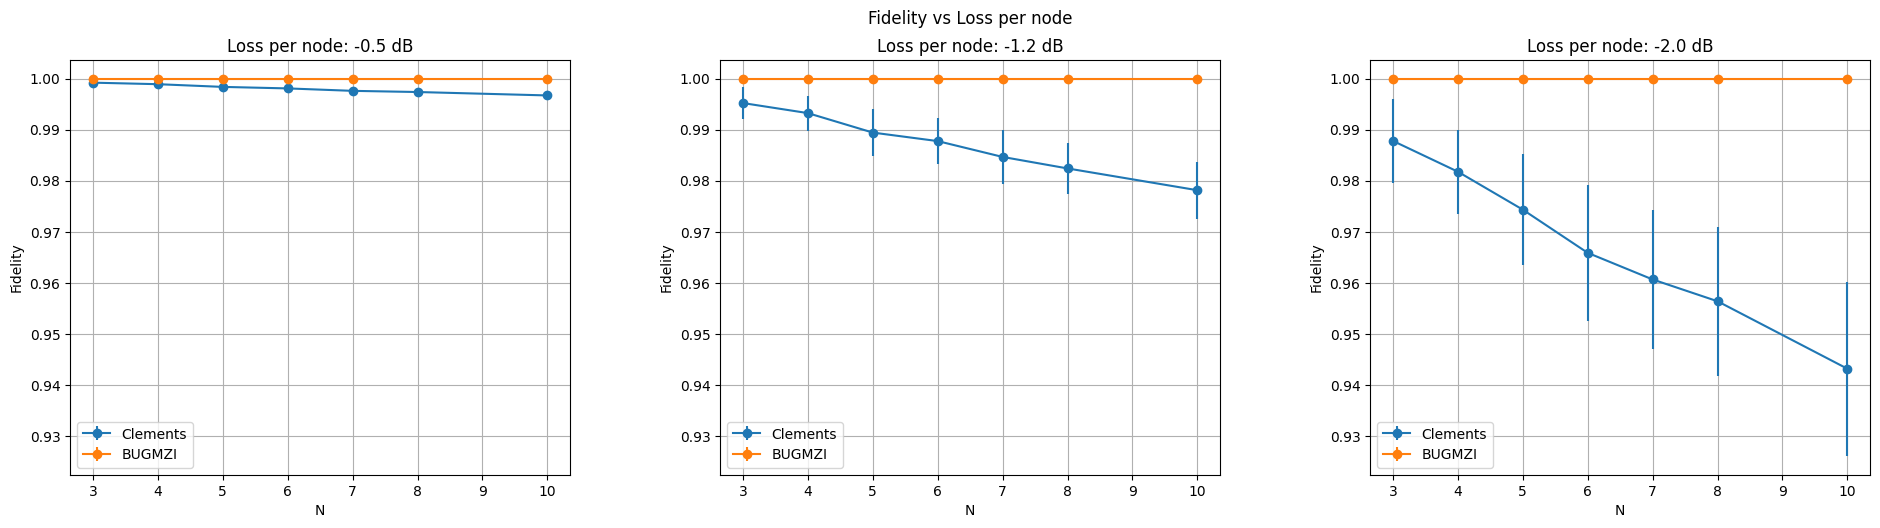

In [35]:
NUM_MODE = [int(n) for n in np.linspace(3,10,7)]
LOSSES = np.linspace(-0.5, -2, 3)
COUNT = 200

# Matplotlib setup
plots = []
fig, plots = plt.subplots(1,3, figsize=(20, 5),sharey=True)
plt.subplots_adjust(left=0.05, right=0.95, bottom=0.05, wspace=0.3, hspace=0.3)
fig.suptitle('Fidelity vs Loss per node')
x = NUM_MODE

for i in range(LOSSES.size):
    ax = plots[i%3]
    ax.set_title(f'Loss per node: {LOSSES[i]:.1f} dB')
    ax.set_xlabel('N')
    ax.set_ylabel('Fidelity')
    ax.grid()
    ax.yaxis.set_tick_params(labelbottom=True)
    
    fidelity = np.zeros((len(NUM_MODE), 2))
    sds = np.zeros((len(NUM_MODE), 2))

    for j in range(len(NUM_MODE)):
        total = np.zeros((COUNT, 2))
        for k in range(COUNT):
            # Compute the circuits
            U = random_unitary(NUM_MODE[j])
            circuit_reck = decompose_reck(U)
            circuit_clements = decompose_clements(U)
            circuit_ugmzi = decompose_ugmzi(U)
            
            # Compute the experimental transformations with losses
            
            # Clements
            Uexp_clements = circuit_clements.calculate_transformation(LN_dB=LOSSES[i])
            total[k, 0] += Fid(U, Uexp_clements)
            
            # BUGMZI
            Uexp_ugmzi = circuit_ugmzi.calculate_transformation(LN_dB=LOSSES[i])
            voa = restorer(NUM_MODE[j], LN_dB=LOSSES[i])
            Uexp_bugmzi = Uexp_ugmzi @ np.diag(voa)
            total[k, 1] += Fid(U, Uexp_bugmzi)

        fidelity[j, 0] = np.mean(total[:, 0])
        fidelity[j, 1] = np.mean(total[:, 1])
        sds[j, 0] = np.std(total[:, 0])
        sds[j, 1] = np.std(total[:, 1])
    
    # Draw the plot
    ax.errorbar(x, fidelity[:, 0], yerr=sds[:, 0], marker='o')
    ax.errorbar(x, fidelity[:, 1], yerr=sds[:, 1], marker='o')

    ax.legend(['Clements', 'BUGMZI'])


plt.show()

We can see that the BUGMZI architecture manages to maintain perfect fidelity for any loss value, whereas Clements' architecture, although it performs better than Reck's and UGMZI, still suffers from decreases in fidelity

## SVD

### SVD For UGMZI And Clements

<p align="center">
    <img src="images/ugmzi_svd.svg" width="70%"/>
</p>

$$
F(M,M_{exp})=\left|\frac{\text{tr}\left(\Sigma^2B_U^{-1}B_V\right)}{\sqrt{\text{tr}\left(\Sigma^2\right)\text{tr}\left(\Sigma^2\left(B_U^{-1}B_V\right)^2\right)}}\right|^2
$$

As we can see from the above formula, if we assume all the component have the same loss indipendent on its size, then the losses of $V^\dagger$ will combine with the losses of $U$ and automatically restore fidelity.
Basically the losses of $V^\dagger$, when brought to the left side of $U$ has the same role as the VOA array in the BUGMZI method

In [13]:
def ugmzi_loss_balancer(N, k):
    """
    For UGMZI, the loss factor for the i-th output is k**(N-i), for the V^T it's k**(i-1), so
    BU = diag([k**(N-1), k**(N-2), ..., k**0])
    BV = diag([k**0, k**1, ..., k**(N-1)])
    """
    BU = np.diag([k**(N-i-1) for i in range(N)])
    BV = np.diag([k**i for i in range(N)])
    return BU, BV

def decompose_svd_ugmzi_balanced(M, LN_dB=0.0, verbose=False):
    U, D, Vh = np.linalg.svd(M)
    N = M.shape[0]
    k = np.sqrt(10 ** (LN_dB / 10)) if LN_dB != 0 else 1.0

    # Decompose U and V^T as UGMZI circuits
    I_U = decompose_ugmzi(U, verbose=verbose)
    U_exp = I_U.calculate_transformation(LN_dB=LN_dB)

    I_V = decompose_ugmzi(Vh.conj().T, verbose=verbose)
    V_exp = I_V.calculate_transformation(LN_dB=LN_dB).conj().T  # gives V^T

    # Sigma (diagonal, with VOA loss included)
    Sigma_exp = k * np.diag(D)

    # Loss balancing matrices 
    BU, BV = ugmzi_loss_balancer(N, k)
    # Combine the losses into Sigma
    Sigma_exp_balanced = np.linalg.inv(BV) @ Sigma_exp @ BU

    # Balanced implementation 
    M_exp_balanced = U_exp @ Sigma_exp_balanced @ V_exp

    return M_exp_balanced, U, D, Vh

In [14]:
def decompose_svd_clements(M, LN_dB=0.0, verbose=False):
    U, D, Vh = np.linalg.svd(M)
    N = M.shape[0]
    k = np.sqrt(10 ** (LN_dB / 10)) if LN_dB != 0 else 1.0

    # Decompose U and V^T as Clements circuits
    I_U = decompose_clements(U, verbose=verbose)
    U_exp = I_U.calculate_transformation(LN_dB=LN_dB)

    I_V = decompose_clements(Vh.conj().T, verbose=verbose)
    V_exp = I_V.calculate_transformation(LN_dB=LN_dB).conj().T  

    # Sigma (diagonal, with VOA loss included)
    Sigma_exp = k * np.diag(D)

    # No loss balancing
    M_exp_clements = U_exp @ Sigma_exp @ V_exp

    return M_exp_clements, U, D, Vh


In [15]:
N = 6
LN_dB = 5
M = np.random.randn(N, N) + 1j * np.random.randn(N, N)

# UGMZI with loss balancing
M_exp_balanced, U_ugmzi, D_ugmzi, Vh_ugmzi = decompose_svd_ugmzi_balanced(M, LN_dB=LN_dB)

# Clements standard (no loss balancing)
M_exp_clements, U_cle, D_cle, Vh_cle = decompose_svd_clements(M, LN_dB=LN_dB)

def Fid_general(M, M_exp):
    numer = np.trace(M.conj().T @ M_exp)
    denom = np.sqrt(np.trace(M.conj().T @ M) * np.trace(M_exp.conj().T @ M_exp))
    return np.abs(numer / denom) ** 2

print("SVD-UGMZI fidelity (balanced):", Fid_general(M, M_exp_balanced))
print("SVD-Clements fidelity (standard):", Fid_general(M, M_exp_clements))


SVD-UGMZI fidelity (balanced): 1.0
SVD-Clements fidelity (standard): 0.6586419599656538


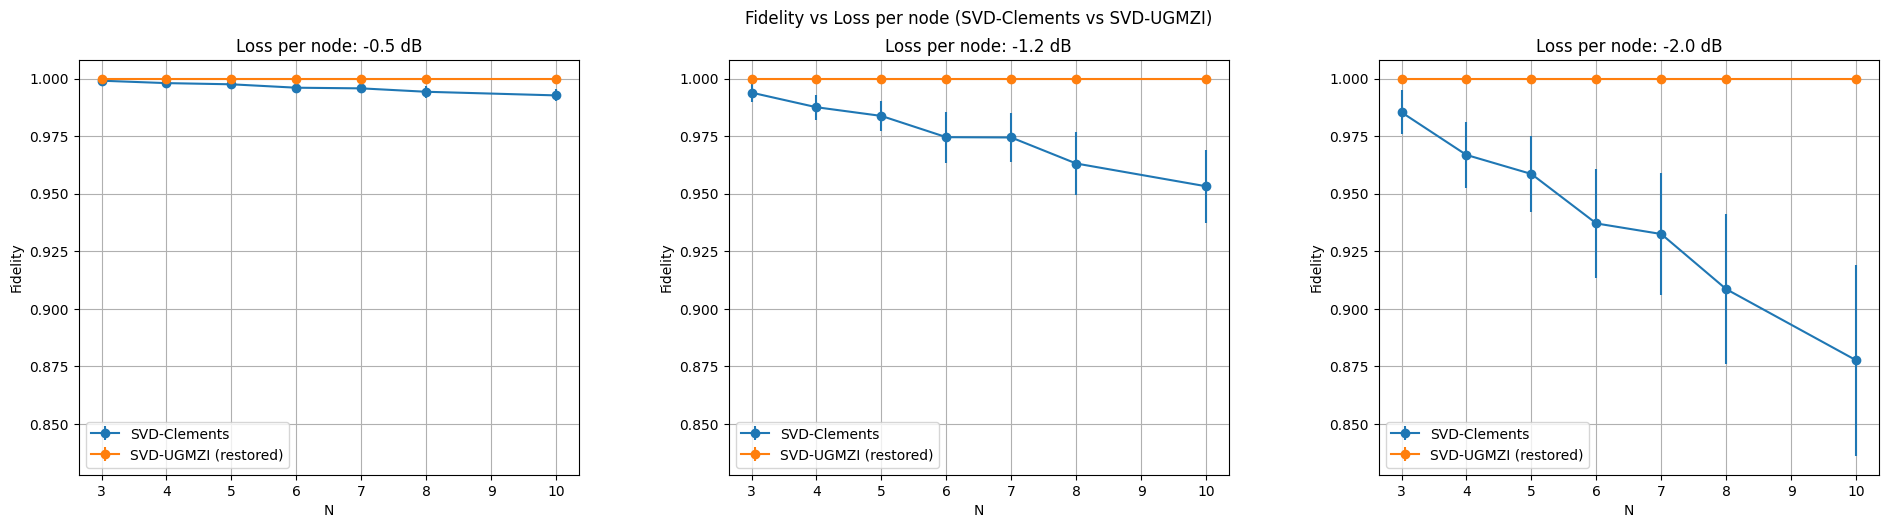

In [30]:
NUM_MODE = [int(n) for n in np.linspace(3,10,7)]
LOSSES = np.linspace(-0.5, -2, 3)
COUNT = 200

fig, plots = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
plt.subplots_adjust(left=0.05, right=0.95, bottom=0.05, wspace=0.3, hspace=0.3)
fig.suptitle('Fidelity vs Loss per node (SVD-Clements vs SVD-UGMZI)')

x = NUM_MODE

for i in range(LOSSES.size):
    ax = plots[i]
    ax.set_title(f'Loss per node: {LOSSES[i]:.1f} dB')
    ax.set_xlabel('N')
    ax.set_ylabel('Fidelity')
    ax.grid()
    ax.yaxis.set_tick_params(labelbottom=True)
    
    fidelity = np.zeros((len(NUM_MODE), 2))
    sds = np.zeros((len(NUM_MODE), 2))

    for n in range(len(NUM_MODE)):
        total = np.zeros((COUNT, 2))
        for k in range(COUNT):
            # Generate random complex matrix (a general matrix, not just unitary!)
            M = np.random.randn(NUM_MODE[n], NUM_MODE[n]) + 1j * np.random.randn(NUM_MODE[n], NUM_MODE[n])
            
            # SVD-UGMZI (balanced restoration)
            M_exp_ugmzi, *_ = decompose_svd_ugmzi_balanced(M, LN_dB=LOSSES[i])
            total[k,1] += Fid_general(M, M_exp_ugmzi)
            
            # SVD-Clements (no restoration)
            M_exp_clements, *_ = decompose_svd_clements(M, LN_dB=LOSSES[i])
            total[k,0] += Fid_general(M, M_exp_clements)

        fidelity[n,0] = np.mean(total[:,0])
        fidelity[n,1] = np.mean(total[:,1])
        sds[n,0] = np.std(total[:,0])
        sds[n,1] = np.std(total[:,1])

    # Draw the plot
    ax.errorbar(x, fidelity[:, 0], yerr=sds[:, 0],marker='o')
    ax.errorbar(x, fidelity[:, 1], yerr=sds[:, 1],marker='o')
    ax.legend(['SVD-Clements', 'SVD-UGMZI (restored)'])

plt.show()


## References

[1] Reck, Michael, et al. "Experimental realization of any discrete unitary operator." Physical review letters 73.1 (1994): 58. <br>
[2] Clements, William R., et al. "Optimal design for universal multiport interferometers." Optica 3.12 (2016): 1460-1465.<br>
[3] Tsakyridis, A., Giamougiannis, G., Totovic, A. and Pleros, N. (2022), Fidelity Restorable Universal Linear Optics. Adv. Photonics Res., 3: 2200001. https://doi.org/10.1002/adpr.202200001<br>
[4] P. Dita, J. Phys. A: Math. Gen. 2006, 36, 2781. <br>
[5] https://github.com/clementsw/interferometer <br>